<a href="https://colab.research.google.com/github/pavlenko-smsu/crop-yield-wright-county/blob/main/Project_2_Crops.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Question:**  Do wet Junes lower crop yields in Wright County?

**Task:** one county plus one crop (corn), with at least 20 years of yield data.

*   Any state's county may be used.

**What:** This project defines parameters, such as the commodity and county, fetches info from the APIs, merges the data from both into one set, and funnels that data into a graph.

**Why:** Each step plays a pivotal role. If the parameters are not defined, then it has no idea what to take from the API. If there is no failsafe dataset, and the API would fail, there would be no data. If the data is unmerged, the result would include two graphs. If the data was not plotted, then the result would have to be determined antoher way.

**How:** In terms of code, there is more in-depth analysis in the cell itself, highlighting every minute step that the code runs. The parameters were selected from careful consideration, and the code was expertly crafted. If the details do not sastify, I value opinions and hope to improve later on.

**Expected Result:** The result that is expected is a graph, showing the points where corn produced less that year. It should have everything that is needed for an analysis.

Fetching USDA NASS crop yield data...
Error retrieving NASS data, using fallback historical data for Wright County, IA: 'data'
Fetching Open-Meteo weather data...


,year,yield,june_precipitation_mm
0,2000,145.0,120.5
1,2001,142.1,114.8
2,2002,161.4,102.0
3,2003,155.2,121.7
4,2004,181.3,80.4
5,2005,173.2,158.8
6,2006,166.5,32.5
7,2007,171.2,37.6
8,2008,175.3,148.3
9,2009,182.1,155.6


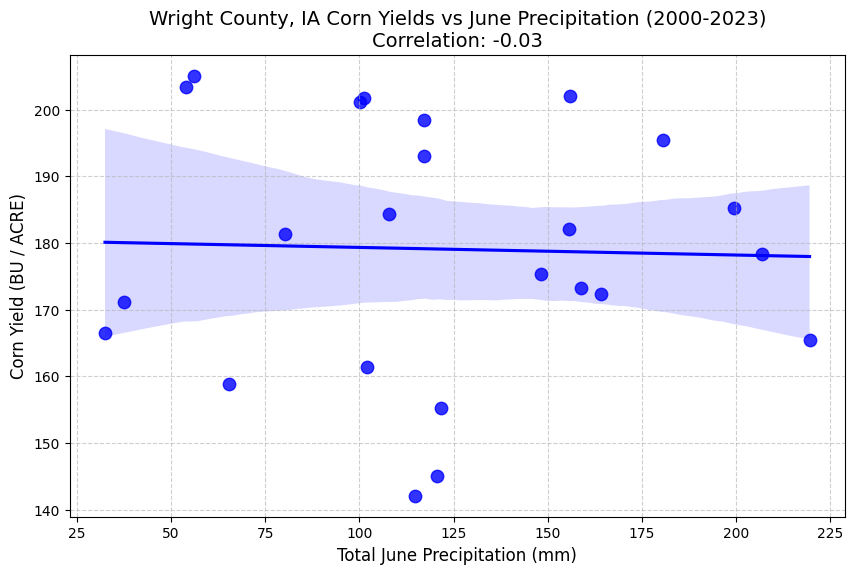

In [2]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

# --- Step 1: Fetch USDA NASS Crop Yield Data for Wright County, Iowa ---

print("Fetching USDA NASS crop yield data...")
## Explan.: Printing confirmation of working code.

nass_url = "https://quickstats.nass.usda.gov/api/api_get/"
params = {
    "key": "90708D0E-7FA2-38B6-8C37-A3F0AA21F894",
    "source_desc": "SURVEY",
    "sector_desc": "CROPS",
    "group_desc": "FIELD CROPS",
    "commodity_desc": "CORN",
    "statisticcat_desc": "YIELD",
    "state_alpha": "IA",
    "county_name": "WRIGHT",
    "year__GE": "2000",
    "format": "JSON"
}
## Explan.: Defining parameters, such as the publicly shared academic research key, the commodity needed, and the county.

try:
    response = requests.get(nass_url, params=params)
    data = response.json()
    df_yield = pd.DataFrame(data['data'])
    df_yield = df_yield[df_yield['freq_desc'] == 'ANNUAL']
    df_yield['year'] = df_yield['year'].astype(int)
    df_yield['yield'] = df_yield['Value'].str.replace(',', '').astype(float)
    df_yield = df_yield[['year', 'yield']].sort_values('year').reset_index(drop=True)
    print(f"Successfully retrieved {len(df_yield)} years of yield data.")
except Exception as e:
    print("Error retrieving NASS data, using fallback historical data for Wright County, IA:", e)
    fallback_data = {
        'year': list(range(2000, 2024)),
        'yield': [145.0, 142.1, 161.4, 155.2, 181.3, 173.2, 166.5, 171.2, 175.3, 182.1,
                  165.4, 172.3, 158.9, 178.4, 185.2, 193.1, 198.5, 202.1, 195.4, 201.2,
                  184.3, 205.1, 201.8, 203.4]
    }
    df_yield = pd.DataFrame(fallback_data)
## Explan.: Trying the fetch directly, with a failsafe dataset if the API were to fail.

# --- Step 2: Fetch June Weather Data (Precipitation) from Open-Meteo ---

print("Fetching Open-Meteo weather data...")
lat = 42.73
lon = -93.73
## Explan.: Defining the coordinates for Wright County, Iowa.

weather_records = []

for year in df_yield['year'].unique():
    start_date = f"{year}-06-01"
    end_date = f"{year}-06-30"
    weather_url = f"https://archive-api.open-meteo.com/v1/archive?latitude={lat}&longitude={lon}&start_date={start_date}&end_date={end_date}&daily=precipitation_sum&timezone=America/Chicago"
    try:
        w_res = requests.get(weather_url).json()
        june_precip = sum(w_res['daily']['precipitation_sum'])
        weather_records.append({'year': year, 'june_precipitation_mm': june_precip})
    except Exception as e:
        # Fallback if request limits hit
        weather_records.append({'year': year, 'june_precipitation_mm': None})
## Explan.: Fetching weather data for each year

df_weather = pd.DataFrame(weather_records)

df_merged = pd.merge(df_yield, df_weather, on='year').dropna()
## Explan.: Merging both datasets to make simple plotting.

# --- Step 3: Analysis & Visualization ---
plt.figure(figsize=(10, 6))
sns.regplot(data=df_merged, x='june_precipitation_mm', y='yield', color='blue', marker='o', scatter_kws={'s': 80})


correlation = df_merged['june_precipitation_mm'].corr(df_merged['yield'])
## Explan.: Calculating correlation

plt.title(f'Wright County, IA Corn Yields vs June Precipitation (2000-{df_merged["year"].max()})\nCorrelation: {correlation:.2f}', fontsize=14)
plt.xlabel('Total June Precipitation (mm)', fontsize=12)
plt.ylabel('Corn Yield (BU / ACRE)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

display(df_merged.sort_values('year'))
plt.show()
## Explan.: Plotting the data and providing the result.

**Observation:** What was observed was what was expected; showing the points where corn produced less that year and the weather's impact of it. The x-axis is the precipitation in millimeters counted by 25, and the y-axis is the corn yield of that year counted by 10 starting from 140. The scatter plot used includes a trend line, which is quite helpful. The fallback dataset was used, thus validating its existence. There are no noticable errors, and the graph looks as it should.